# 02 – First Model: From Risk Score to Lending Decision

> **Project notebooks:** [01 Exploration](01_exploration.ipynb) · [02 First model](02_first_model.ipynb)

**Goal of this notebook:** build a first credit risk model, check whether the cleaning from notebook 01 helps, and learn the step that the Titanic and house price projects did not need: turning a **risk score** into a **decision**.

**Contents**
1. Setup
2. Baselines: how good is "good"?
3. Logistic regression: raw data vs. cleaned data
4. Gradient boosting
5. Comparing the models
6. From risk score to decision: choosing a threshold
7. First Kaggle submission
8. Conclusions

## 1. Setup

As in the loan project we measure with **ROC AUC** (how often a defaulter gets a higher risk score than a non‑defaulter; 0.5 = coin flip, 1 = perfect) and **average precision** (how pure the top of the risk list is; a model that guesses gets the default rate, 0.067). Kaggle scores this competition with ROC AUC.

Every model is a pipeline that starts from the raw file, so the cleaning is learned inside each fold (the lesson from the Titanic project).

In [1]:
import sys
sys.path.append("..")   # the project folder, where src/ lives

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from src.features import CreditFeatures, LATE_COLUMNS, TARGET, load, log_positive, raw_columns

warnings.filterwarnings("ignore", category=FutureWarning)  # hide a harmless seaborn/pandas version notice
sns.set_theme(style="whitegrid", palette="Set2")

df = load("../data/cs-training.csv")
test_raw = load("../data/cs-test.csv")
y = df[TARGET].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results, risk_scores = {}, {}


def evaluate(name, scores):
    "Store ROC AUC and average precision of out-of-fold risk scores."
    risk_scores[name] = scores
    results[name] = {"ROC AUC": roc_auc_score(y, scores), "average precision": average_precision_score(y, scores)}
    return pd.DataFrame(results).T.round(4)


def cv_scores(model):
    return cross_val_predict(model, df, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]


print(f"Borrowers: {len(df):,}, default rate {y.mean():.2%}")

Borrowers: 150,000, default rate 6.68%


## 2. Baselines: how good is "good"?

Two baselines before any real model:

1. **Nobody defaults**: gives every borrower the same score. AUC 0.5 by definition.
2. **A one‑line rule**: "risky if the borrower was late at least once in the last two years". The kind of rule a bank clerk could apply without a computer. Its "score" is just 1 or 0.

In [2]:
evaluate("Baseline: nobody defaults", np.zeros(len(df)))

late_counts = df[LATE_COLUMNS].where(df[LATE_COLUMNS] < 96, 0)
evaluate("Baseline: rule 'ever late'", (late_counts.sum(axis=1) > 0).astype(float).to_numpy())

,ROC AUC,average precision
Baseline: nobody defaults,0.500,0.0668
Baseline: rule 'ever late',0.746,0.1678


The one‑line rule already reaches an AUC of **0.75**. Any model we build has to beat that clearly to be worth its complexity.

## 3. Logistic regression: raw data vs. cleaned data

**Logistic regression** is the classic credit scoring model, used by banks for decades. It is a linear model like Ridge, but it predicts a probability between 0 and 1. Banks like it because each feature gets one weight that can be explained to a customer or a regulator.

We train it three times:
1. on the **raw** columns, missing values filled with the median,
2. after the **cleaning** from notebook 01 (`CreditFeatures`),
3. after cleaning **and** a log transformation of all numbers, because most columns are very skewed.

In [3]:
%%time
def logistic_pipeline(*first_steps):
    return make_pipeline(*first_steps, SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(max_iter=2000))


evaluate("Logistic regression, raw data", cv_scores(logistic_pipeline(FunctionTransformer(raw_columns))))
evaluate("Logistic regression, cleaned", cv_scores(logistic_pipeline(CreditFeatures())))
evaluate("Logistic regression, cleaned + log", cv_scores(
    logistic_pipeline(CreditFeatures(), SimpleImputer(strategy="median"), FunctionTransformer(log_positive))))

CPU times: user 229 ms, sys: 125 ms, total: 354 ms
Wall time: 4.24 s


,ROC AUC,average precision
Baseline: nobody defaults,0.5000,0.0668
Baseline: rule 'ever late',0.7460,0.1678
"Logistic regression, raw data",0.6984,0.2334
"Logistic regression, cleaned",0.8366,0.3579
"Logistic regression, cleaned + log",0.8549,0.3700


A dramatic result:

- On the **raw** data, logistic regression scores an AUC of **0.70**, *worse than the one‑line rule*. A few absurd values (utilisation of 50,708, debt ratios in the thousands, the 98 codes) dominate a linear model: it bends its whole line to fit them.
- With the **cleaning** from notebook 01, the AUC jumps to **0.84**.
- With cleaning **and** the log transformation, it reaches **0.855**.

The model did not change at all. **The data preparation alone was worth 0.15 AUC.** In notebook 01 the cleaning decisions may have looked like small details; this is what they are worth.

## 4. Gradient boosting

We now try a tree model. Instead of `GradientBoostingClassifier`, which we used before, we use **`HistGradientBoostingClassifier`**, scikit‑learn's faster version for large datasets. It first sorts each column's values into at most 255 bins, which makes training on 150,000 rows take seconds instead of minutes. It also handles **missing values by itself**: at every split it learns whether borrowers with a missing value should go left or right.

Again we compare raw and cleaned data.

In [4]:
%%time
boosting = HistGradientBoostingClassifier(random_state=42)

evaluate("Gradient boosting, raw data", cv_scores(make_pipeline(FunctionTransformer(raw_columns), boosting)))
evaluate("Gradient boosting, cleaned", cv_scores(make_pipeline(CreditFeatures(), boosting)))

CPU times: user 135 ms, sys: 17.2 ms, total: 152 ms
Wall time: 3.46 s


,ROC AUC,average precision
Baseline: nobody defaults,0.5000,0.0668
Baseline: rule 'ever late',0.7460,0.1678
"Logistic regression, raw data",0.6984,0.2334
"Logistic regression, cleaned",0.8366,0.3579
"Logistic regression, cleaned + log",0.8549,0.3700
"Gradient boosting, raw data",0.8647,0.3999
"Gradient boosting, cleaned",0.8644,0.3987


Gradient boosting reaches an AUC of **0.865**, and here the cleaning makes **no difference** at all.

This is the same lesson as in the house price project, in a stronger form. Trees only ask "is this value above or below a threshold?", so an absurd value of 50,708 simply lands in the highest bin and does no harm. The 98 codes end up in their own branch, and missing incomes are handled by the model itself. Linear models need clean data; tree models mostly do not.

We keep the cleaning anyway. It costs nothing for the tree model, it is essential for the linear one, and the cleaned columns (`IncomeMissing`, `NoCreditHistoryCode`, …) are easier to explain.

## 5. Comparing the models

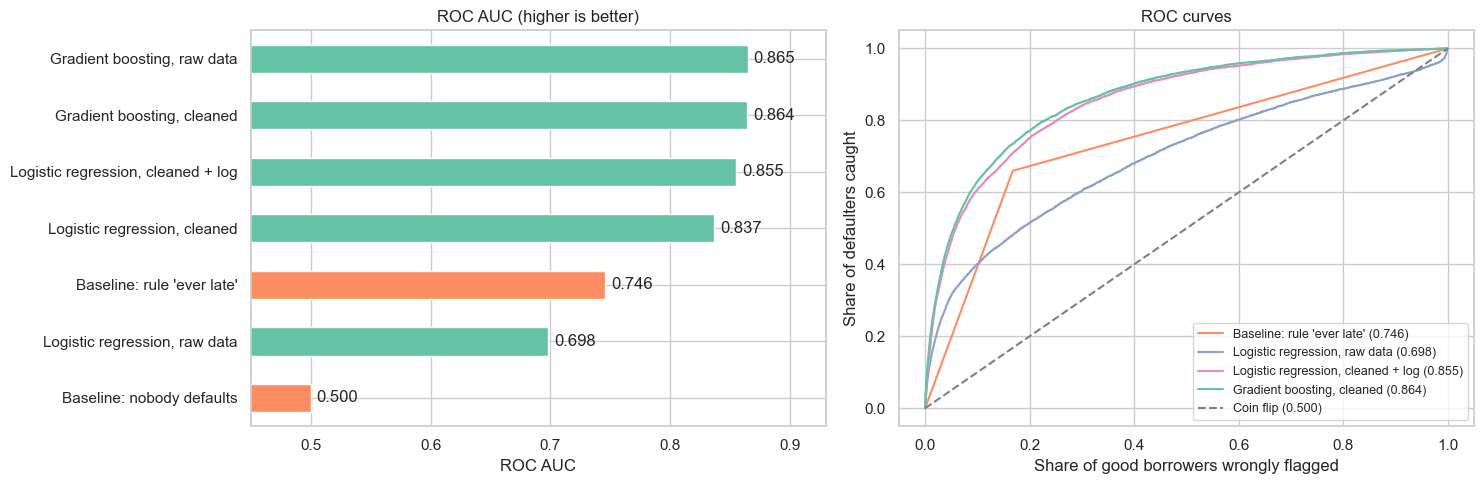

In [5]:
table = pd.DataFrame(results).T

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ordered = table["ROC AUC"].sort_values()
ordered.plot.barh(ax=axes[0], color=["C1" if "Baseline" in name else "C0" for name in ordered.index])
for i, value in enumerate(ordered):
    axes[0].text(value + 0.005, i, f"{value:.3f}", va="center")
axes[0].set(title="ROC AUC (higher is better)", xlabel="ROC AUC")
axes[0].set_xlim(0.45, 0.93)

for name, color in [("Baseline: rule 'ever late'", "C1"), ("Logistic regression, raw data", "C2"),
                    ("Logistic regression, cleaned + log", "C3"), ("Gradient boosting, cleaned", "C0")]:
    false_alarms, caught, _ = roc_curve(y, risk_scores[name])
    axes[1].plot(false_alarms, caught, label=f"{name} ({results[name]['ROC AUC']:.3f})", color=color)
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Coin flip (0.500)")
axes[1].set(title="ROC curves", xlabel="Share of good borrowers wrongly flagged", ylabel="Share of defaulters caught")
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("../images/model_comparison.png", dpi=120)
plt.show()

Gradient boosting is best, the cleaned logistic regression a close second, and both are far above the one‑line rule. An AUC of 0.865 is about what the winners of the original competition achieved (around 0.87), so even this first model is in the right range.

For comparison with the loan project: there the "honest" AUC was 0.50. Here it is 0.865 with an honest random split, because these columns describe real credit behaviour and the data has no copies.

## 6. From risk score to decision: choosing a threshold

The model gives every applicant a **risk score**, for example "8% chance of serious trouble". But a bank has to say **yes or no**. It does that with a **threshold**: reject everyone whose score is above it.

The obvious choice is 50%: reject if trouble is more likely than not. Let's see what that does, using the out‑of‑fold scores of the gradient boosting model:

In [6]:
best_scores = risk_scores["Gradient boosting, cleaned"]


def decision_table(threshold):
    rejected = best_scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y, rejected).ravel()
    return {
        "threshold": threshold,
        "applicants rejected": rejected.mean(),
        "defaulters caught": tp / (tp + fn),
        "good borrowers rejected": fp / (fp + tn),
        "share of rejected who would have defaulted": tp / max(tp + fp, 1),
        "missed defaulters": fn,
        "good borrowers rejected (count)": fp,
    }


pd.DataFrame([decision_table(0.5)]).set_index("threshold").T

threshold,0.5
applicants rejected,0.020307
defaulters caught,0.182825
good borrowers rejected,0.008666
share of rejected who would have defaulted,0.601773
missed defaulters,8193.000000
good borrowers rejected (count),1213.000000


With a threshold of 50% the bank rejects only **2%** of applicants, and it catches only **18% of the defaulters**: more than four out of five still get their loan. Why? Because defaulters are rare. Even for a risky borrower, a 30% or 40% chance of trouble is much higher than average (6.7%) but still below 50%. The 50% threshold is only right if both kinds of mistake cost the same.

### The two mistakes do not cost the same

| Mistake | What it costs the bank (illustrative) |
|---|---|
| **Missed defaulter**: lending to someone who then gets into serious trouble | the lost loan, collection costs: say **\$5,000** |
| **Rejected good borrower**: refusing someone who would have paid back | the lost interest profit: say **\$1,000** |

These numbers are **assumptions** for illustration. In a real bank they would come from the finance department. What matters is the ratio: here a missed defaulter costs **5 times** as much as a rejected good borrower.

With the costs written down, we can calculate the total cost of every possible threshold and pick the cheapest:

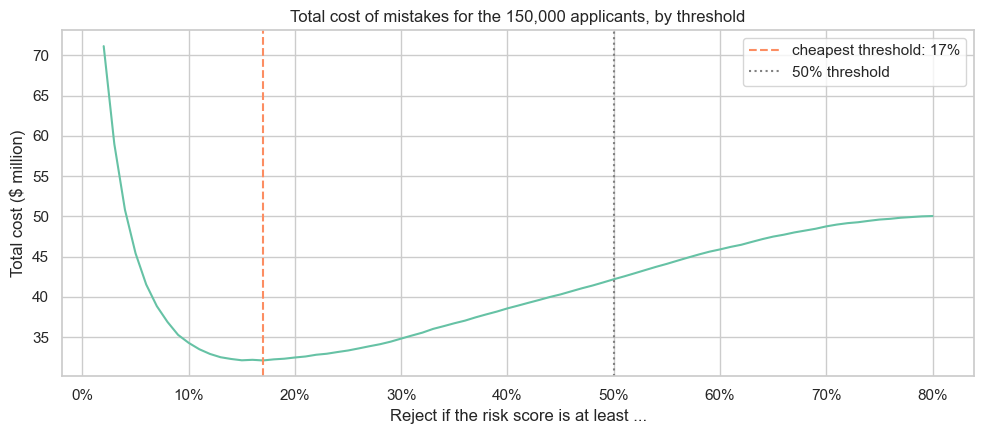

threshold,0.50,0.17
applicants rejected,0.020307,0.106167
defaulters caught,0.182825,0.564632
good borrowers rejected,0.008666,0.073328
share of rejected who would have defaulted,0.601773,0.355479
missed defaulters,8193.000000,4365.000000
good borrowers rejected (count),1213.000000,10264.000000
total cost ($m),42.178000,32.089000


In [7]:
COST_MISSED_DEFAULTER = 5_000
COST_REJECTED_GOOD = 1_000

thresholds = np.round(np.arange(0.02, 0.81, 0.01), 2)
costs = pd.DataFrame([decision_table(t) for t in thresholds]).set_index("threshold")
costs["total cost ($m)"] = (costs["missed defaulters"] * COST_MISSED_DEFAULTER
                            + costs["good borrowers rejected (count)"] * COST_REJECTED_GOOD) / 1e6
best_threshold = costs["total cost ($m)"].idxmin()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(costs.index, costs["total cost ($m)"], color="C0")
ax.axvline(best_threshold, color="C1", linestyle="--", label=f"cheapest threshold: {best_threshold:.0%}")
ax.axvline(0.5, color="grey", linestyle=":", label="50% threshold")
ax.set(title="Total cost of mistakes for the 150,000 applicants, by threshold",
       xlabel="Reject if the risk score is at least ...", ylabel="Total cost ($ million)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
plt.tight_layout()
plt.savefig("../images/threshold_cost.png", dpi=120)
plt.show()

comparison = pd.DataFrame([decision_table(0.5), decision_table(best_threshold)]).set_index("threshold")
comparison["total cost ($m)"] = costs.loc[[0.5, best_threshold], "total cost ($m)"].values
comparison.T

The cheapest threshold is **17%**, far below 50%:

| | Threshold 50% | Threshold 17% |
|---|---|---|
| Applicants rejected | 2% | 11% |
| Defaulters caught | 18% | **56%** |
| Good borrowers wrongly rejected | 0.9% | 7.3% |
| Of the rejected, would really have defaulted | 60% | 36% |
| Total cost of mistakes | \$42.2 million | **\$32.1 million** |

With the lower threshold the bank rejects many more good borrowers (about 10,000 instead of 1,200), and still saves about **\$10 million**, a quarter of the cost, because it now catches more than half of the expensive defaulters.

**A useful rule of thumb.** If the model's risk scores are good probabilities, the cheapest threshold is

> cost of rejecting a good borrower ÷ (cost of rejecting a good borrower + cost of a missed defaulter) = 1,000 ÷ 6,000 ≈ **17%**,

exactly what we found by trying all thresholds. It also shows how the decision depends on the business: if a missed defaulter cost 10 times as much as a rejected good borrower, the threshold would drop to about 9%.

**Lessons**
- The **model** produces a ranking of risk. The **threshold** is a business decision, and it should come from the costs of the two kinds of mistake, not from the habit of using 50%.
- With rare events, a good threshold is usually far below 50%.
- (We chose the threshold using the same out‑of‑fold scores we evaluate it on, so the \$10 million saving is slightly optimistic. With 150,000 borrowers the effect is small.)

## 7. First Kaggle submission

Kaggle does not want yes/no decisions but the **risk scores** themselves, because it measures ROC AUC, which looks at the ranking of all applicants. We train the gradient boosting pipeline on all 150,000 borrowers and predict the 101,503 applicants in `cs-test.csv`.

In [8]:
from pathlib import Path

final_model = make_pipeline(CreditFeatures(), HistGradientBoostingClassifier(random_state=42)).fit(df, y)

submission = pd.DataFrame({"Id": test_raw["Id"], "Probability": final_model.predict_proba(test_raw)[:, 1]})
Path("../submissions").mkdir(exist_ok=True)
submission.to_csv("../submissions/submission_v1_boosting.csv", index=False)

print(f"Saved {len(submission):,} predictions to submissions/submission_v1_boosting.csv")
print(f"Average predicted risk: {submission['Probability'].mean():.2%} (training default rate: {y.mean():.2%})")
submission.head()

Saved 101,503 predictions to submissions/submission_v1_boosting.csv
Average predicted risk: 6.71% (training default rate: 6.68%)


,Id,Probability
0,1,0.066986
1,2,0.041662
2,3,0.015506
3,4,0.076969
4,5,0.108468


Upload `submissions/submission_v1_boosting.csv` on the [competition page](https://www.kaggle.com/c/GiveMeSomeCredit/submit) (**Late Submission**, because the competition has ended).

Kaggle shows two scores: a **public** score, calculated on one part of the test applicants, and a **private** score, calculated on the rest. The private score decided the final ranking of the competition, and it uses the larger part of the test data.

| Submission | Model | CV ROC AUC | Kaggle public | Kaggle private |
|---|---|---|---|---|
| v1 | Gradient boosting, cleaned features | 0.8644 | _fill in_ | _fill in_ |

## 8. Conclusions

**What we found**

| Model | ROC AUC |
|---|---|
| Rule "ever late" | 0.746 |
| Logistic regression, raw data | 0.698 |
| Logistic regression, cleaned + log | 0.855 |
| **Gradient boosting, cleaned** | **0.864** |

- **Cleaning was worth 0.15 AUC for logistic regression** and nothing for gradient boosting. Linear models need clean data; tree models mostly do not.
- **Gradient boosting** is the best first model, at about the level of the original competition's winners.
- **The threshold matters as much as the model.** With illustrative costs, a 17% threshold instead of 50% saves about a quarter of the cost of mistakes.

**What we learned**

| Concept | In one sentence |
|---|---|
| **Logistic regression** | The classic, explainable credit scoring model; it needs clean data. |
| **HistGradientBoosting** | A fast gradient boosting model for large data that handles missing values by itself. |
| **Threshold** | Turns a risk score into a decision; it is a business choice, not a technical default. |
| **Costs of mistakes** | When a missed defaulter costs more than a rejected good borrower, the best threshold drops far below 50%. |

**Ideas for the next notebook**
- Tune gradient boosting and blend it with logistic regression.
- Check whether the risk scores are good **probabilities** (calibration): when the model says 10%, do 10% really default?
- Explain the model with SHAP, and think about **fairness**: should age influence a lending decision?